In [22]:
import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt


In [23]:
students = pd.read_csv("students_100.csv")

X = torch.tensor(
    students[["study_hours","phone_hours"]].values,
    dtype=torch.float32
)

Y = torch.tensor(
    students[["maths"]].values,
    dtype=torch.float32
)

print(X.shape, Y.shape)


torch.Size([100, 2]) torch.Size([100, 1])


Epoch 0: Loss = 3031.186767578125
Epoch 10: Loss = 957.964111328125
Epoch 20: Loss = 508.0158996582031
Epoch 30: Loss = 232.31521606445312
Epoch 40: Loss = 234.50927734375
Epoch 50: Loss = 192.1180419921875
Epoch 60: Loss = 157.88565063476562
Epoch 70: Loss = 138.01406860351562
Epoch 80: Loss = 121.81999969482422
Epoch 90: Loss = 108.2605209350586
Epoch 100: Loss = 97.7402572631836
Epoch 110: Loss = 90.01454162597656
Epoch 120: Loss = 84.44474792480469
Epoch 130: Loss = 80.3339614868164
Epoch 140: Loss = 77.07026672363281
Epoch 150: Loss = 74.23448181152344
Epoch 160: Loss = 71.6124038696289
Epoch 170: Loss = 69.13013458251953
Epoch 180: Loss = 66.78036499023438
Epoch 190: Loss = 64.57501983642578
Epoch 200: Loss = 62.52663040161133
Epoch 210: Loss = 60.644500732421875
Epoch 220: Loss = 58.93498229980469
Epoch 230: Loss = 57.401668548583984
Epoch 240: Loss = 56.045040130615234
Epoch 250: Loss = 54.862281799316406
Epoch 260: Loss = 53.847068786621094
Epoch 270: Loss = 52.98992156982422


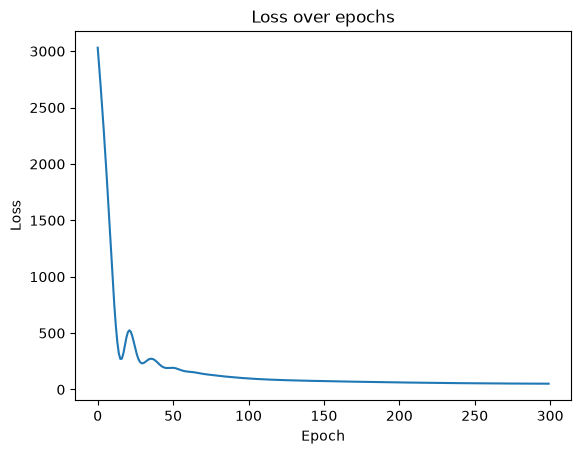

In [24]:
torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(2, 3),
    nn.ReLU(),
    nn.Linear(3, 1),
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

losses = []
for epoch in range(300):
    guess = model(X)
    loss = loss_fn(guess, Y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item()}")

plt.plot(losses)
plt.title("Loss over epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [25]:
with torch.no_grad():
    new_data = torch.tensor([[5, 0]], dtype=torch.float32)
    
    print("5 study hours, 0 phone hours -",round(model(new_data).item(), 2),"marks")

    

5 study hours, 0 phone hours - 87.05 marks
